In [6]:
   %pip install pgmpy

Note: you may need to restart the kernel to use updated packages.


In [7]:
import os
os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

In [8]:
import pgmpy
print(pgmpy.__version__)

1.1.2


In [9]:
import pandas as pd

dati = pd.read_pickle("../data/dataset_kb.pkl")
si_no = {1: "si", 0: "no"}

rete_dati = pd.DataFrame(index=dati.index)
rete_dati["apprezzato"] = dati["apprezzato"].map(si_no)
rete_dati["prezzo"] = pd.cut(dati["prezzo"], bins=[-1, 0, 5, 15, float("inf")],
                             labels=["gratis", "basso", "medio", "alto"]).astype(str)
rete_dati["multipiattaforma"] = ((dati["mac"] == 1) | (dati["linux"] == 1)).astype(int).map(si_no)
rete_dati["autopubblicato"] = dati["autopubblicato"].map(si_no)
rete_dati["esperienza"] = pd.cut(dati["esperienza_dev"], bins=[-1, 0, 5, float("inf")],
                                 labels=["esordiente", "alcuni", "prolifico"]).astype(str)
rete_dati["early_access"] = dati["genere_Early Access"].map(si_no)
rete_dati["indie"] = dati["genere_Indie"].map(si_no)

for col in rete_dati.columns:
    print(col, rete_dati[col].value_counts(normalize=True).round(3).to_dict())

apprezzato {'si': 0.535, 'no': 0.465}
prezzo {'basso': 0.577, 'medio': 0.241, 'gratis': 0.13, 'alto': 0.051}
multipiattaforma {'no': 0.732, 'si': 0.268}
autopubblicato {'si': 0.703, 'no': 0.297}
esperienza {'esordiente': 0.545, 'alcuni': 0.314, 'prolifico': 0.141}
early_access {'no': 0.918, 'si': 0.082}
indie {'si': 0.716, 'no': 0.284}


In [10]:
for col in ["genere_Early Access", "genere_Indie"]:
    print(col, dati.groupby(col)["apprezzato"].mean().round(3).to_dict())

print(pd.crosstab(dati["genere_Indie"], dati["autopubblicato"], normalize="index").round(3))

genere_Early Access {0: 0.543, 1: 0.443}
genere_Indie {0: 0.509, 1: 0.545}
autopubblicato      0      1
genere_Indie                
0               0.413  0.587
1               0.252  0.748


C:\Users\dmiva\.conda\envs\anaconda-mcp\envs\progetto_icon\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\dmiva\.conda\envs\anaconda-mcp\envs\progetto_icon\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (
C:\Users\dmiva\AppData\Local\Temp\ipykernel_11024\2260593684.py:8: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(rete_dati[variabili])


Frecce trovate: [('apprezzato', 'multipiattaforma'), ('prezzo', 'early_access'), ('prezzo', 'apprezzato'), ('prezzo', 'autopubblicato'), ('autopubblicato', 'apprezzato'), ('autopubblicato', 'multipiattaforma'), ('esperienza', 'prezzo'), ('esperienza', 'early_access'), ('early_access', 'autopubblicato'), ('early_access', 'apprezzato'), ('early_access', 'multipiattaforma')]


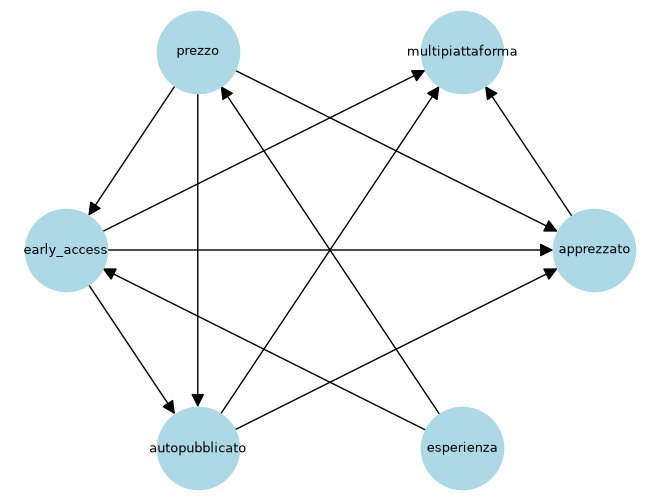

In [11]:
variabili = ["apprezzato", "prezzo", "multipiattaforma", "autopubblicato",
             "esperienza", "early_access"]

from pgmpy.estimators import HillClimbSearch
import networkx as nx
import matplotlib.pyplot as plt

hc = HillClimbSearch(rete_dati[variabili])
try:
    struttura = hc.estimate(scoring_method="bic-d", show_progress=False)
except ValueError:
    struttura = hc.estimate(scoring_method="bicscore", show_progress=False)

print("Frecce trovate:", list(struttura.edges()))

grafo = nx.DiGraph(list(struttura.edges()))
grafo.add_nodes_from(variabili)
posizioni = nx.circular_layout(grafo)
nx.draw(grafo, posizioni, with_labels=True, node_size=3500,
        node_color="lightblue", font_size=9, arrowsize=20)
plt.show()

In [13]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator

rete = DiscreteBayesianNetwork(list(struttura.edges()))
rete.add_nodes_from(variabili)

stimatore = BayesianEstimator(rete, rete_dati[variabili])
cpt = stimatore.get_parameters(prior_type="BDeu", equivalent_sample_size=10)
rete.add_cpds(*cpt)

print("Modello valido:", rete.check_model())
print(rete.get_cpds("apprezzato"))

Modello valido: True
+----------------+-----+--------------------+
| autopubblicato | ... | autopubblicato(si) |
+----------------+-----+--------------------+
| early_access   | ... | early_access(si)   |
+----------------+-----+--------------------+
| prezzo         | ... | prezzo(medio)      |
+----------------+-----+--------------------+
| apprezzato(no) | ... | 0.4973344439816743 |
+----------------+-----+--------------------+
| apprezzato(si) | ... | 0.5026655560183257 |
+----------------+-----+--------------------+


C:\Users\dmiva\AppData\Local\Temp\ipykernel_11024\1039352236.py:7: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  stimatore = BayesianEstimator(rete, rete_dati[variabili])


In [14]:
from pgmpy.inference import VariableElimination

inferenza = VariableElimination(rete)

def prob(variabile, evidenza=None):
    ris = inferenza.query([variabile], evidence=evidenza)
    return {stato: round(float(p), 3)
            for stato, p in zip(ris.state_names[variabile], ris.values)}

In [15]:
print("Nessuna evidenza:  ", prob("apprezzato"))
print("Early Access sì:   ", prob("apprezzato", {"early_access": "si"}))
print("Early Access no:   ", prob("apprezzato", {"early_access": "no"}))
print()
for fascia in ["gratis", "basso", "medio", "alto"]:
    print(f"Prezzo {fascia:<7}:   ", prob("apprezzato", {"prezzo": fascia}))
print()
print("Caso favorevole:   ", prob("apprezzato", {"autopubblicato": "si",
                                                  "multipiattaforma": "si",
                                                  "early_access": "no"}))
print("Caso sfavorevole:  ", prob("apprezzato", {"autopubblicato": "no",
                                                  "multipiattaforma": "no",
                                                  "early_access": "si"}))

Nessuna evidenza:   {'no': 0.465, 'si': 0.535}
Early Access sì:    {'no': 0.557, 'si': 0.443}
Early Access no:    {'no': 0.457, 'si': 0.543}

Prezzo gratis :    {'no': 0.535, 'si': 0.465}
Prezzo basso  :    {'no': 0.472, 'si': 0.528}
Prezzo medio  :    {'no': 0.405, 'si': 0.595}
Prezzo alto   :    {'no': 0.487, 'si': 0.513}

Caso favorevole:    {'no': 0.36, 'si': 0.64}
Caso sfavorevole:   {'no': 0.584, 'si': 0.416}


In [16]:
print("Esperienza (nessuna evidenza):  ", prob("esperienza"))
print("Esperienza | non apprezzato:    ", prob("esperienza", {"apprezzato": "no"}))
print("Early Access (nessuna evidenza):", prob("early_access"))
print("Early Access | non apprezzato:  ", prob("early_access", {"apprezzato": "no"}))
print()

print("Solo l'esperienza come evidenza:")
for esp in ["esordiente", "alcuni", "prolifico"]:
    print(f"  {esp:<11}", prob("apprezzato", {"esperienza": esp}))

contesto = {"prezzo": "basso", "early_access": "no",
            "autopubblicato": "si", "multipiattaforma": "no"}
print("Esperienza + contesto fissato:")
for esp in ["esordiente", "alcuni", "prolifico"]:
    print(f"  {esp:<11}", prob("apprezzato", {**contesto, "esperienza": esp}))

Esperienza (nessuna evidenza):   {'alcuni': 0.314, 'esordiente': 0.545, 'prolifico': 0.141}
Esperienza | non apprezzato:     {'alcuni': 0.31, 'esordiente': 0.552, 'prolifico': 0.138}
Early Access (nessuna evidenza): {'no': 0.917, 'si': 0.083}
Early Access | non apprezzato:   {'no': 0.901, 'si': 0.099}

Solo l'esperienza come evidenza:
  esordiente  {'no': 0.47, 'si': 0.53}
  alcuni      {'no': 0.46, 'si': 0.54}
  prolifico   {'no': 0.457, 'si': 0.543}
Esperienza + contesto fissato:
  esordiente  {'no': 0.467, 'si': 0.533}
  alcuni      {'no': 0.467, 'si': 0.533}
  prolifico   {'no': 0.467, 'si': 0.533}
